In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.preprocessing import Normalizer

In [2]:
avepdc = pd.read_csv('~/scRNAseq/analysis/data/avepdc5lin.csv', index_col = 0)
#avepdc.iloc[:,:] = Normalizer(norm='l1').fit_transform(avepdc)
avepdc = avepdc.sub(avepdc.min(axis=1),axis=0)
#avepdc = avepdc.divide(pd.DataFrame(np.sort(avepdc), index=avepdc.index).iloc[:,-2],axis=0)
avepdc = avepdc.divide(avepdc.max(axis=1),axis=0)

In [3]:
bin = 10
col = ['RNA.wt_{}'.format(i+1) for i in range(bin)] + ['RNA.ko_{}'.format(i+1) for i in range(bin)]
col = [ i for i in col if i in avepdc.columns]
col

['RNA.wt_1',
 'RNA.wt_2',
 'RNA.wt_3',
 'RNA.wt_4',
 'RNA.wt_5',
 'RNA.wt_6',
 'RNA.wt_7',
 'RNA.wt_8',
 'RNA.wt_9',
 'RNA.wt_10',
 'RNA.ko_1',
 'RNA.ko_2',
 'RNA.ko_3',
 'RNA.ko_4',
 'RNA.ko_5',
 'RNA.ko_6',
 'RNA.ko_7',
 'RNA.ko_8',
 'RNA.ko_9',
 'RNA.ko_10']

In [4]:
row = [ i for i in [
 'Gm47283',
 'Rnpep',
 'Cd34',
 'Dbi',
 'Egfl7',
 'Emb',
 'Rpsa',
 'Pim1',
 'Pak1',
 'Mid1',
 'Slamf1',
 'H3f3a',
 'Tmem176a',
 'Il12a',
 'Mgst2',
 'Gm35082',
 'Elovl6',
 'Lgals1',
 'Bloc1s2',
 'Cd7',
 'Ifi27l2a',
 'Rgs18',
 'Rcsd1',
 'Ly6a',
 'Cd82',
 'Wdfy1',
 'Ppfia4',
 'Btg2',
 'Jund'] if i in list(avepdc.index.values)]


In [5]:
avepdc = avepdc[col]
avepdc = avepdc.reindex(row)

In [6]:
#cols = list(avepdc.columns.values)
#wt = avepdc.filter(like='RNA.wt', axis=1)
#wt.columns = wt.columns.str[7:]
#wt.columns = wt.columns.astype(int)
#wt = wt.sort_index(axis=1)
#ko = avepdc.filter(like='RNA.ko', axis=1)
#ko.columns = ko.columns.str[7:]
#ko.columns = ko.columns.astype(int)
#ko = ko.sort_index(axis=1)

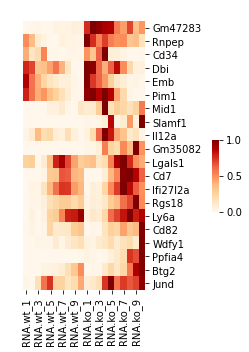

In [7]:
g = sns.clustermap(avepdc, 
                   cmap="OrRd", 
                   #vmin=-2, 
                   vmax=1,
                   #center=0,
                   metric="correlation",
                   method="average",
                   col_cluster=False,
                   row_cluster=False, 
                   figsize= (3, 5),
                   dendrogram_ratio=(.1, 0.05),
                   cbar_pos=(1, 0.4, .03, .2))
# use inkscape instead
#g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticks(), size = 6)

In [14]:
g.savefig('DEGFigure/pdcdown.pdf')

In [8]:
# manually arrange rows
#list(avepdc.iloc[g.dendrogram_row.reordered_ind].index.values)
row

['Gm47283',
 'Rnpep',
 'Cd34',
 'Dbi',
 'Emb',
 'Pim1',
 'Mid1',
 'Slamf1',
 'Il12a',
 'Gm35082',
 'Lgals1',
 'Cd7',
 'Ifi27l2a',
 'Rgs18',
 'Ly6a',
 'Cd82',
 'Wdfy1',
 'Ppfia4',
 'Btg2',
 'Jund']

In [10]:
avepdclo = pd.read_csv('~/scRNAseq/analysis/data/avepdc5linlo.csv', index_col = 0)
avepdclo = avepdclo.sub(avepdclo.min(axis=1),axis=0)
avepdclo = avepdclo.divide(avepdclo.max(axis=1),axis=0)
bin = 10
col = ['RNA.wt_{}'.format(i+1) for i in range(bin)] + ['RNA.ko_{}'.format(i+1) for i in range(bin)]
col = [ i for i in col if i in avepdclo.columns]
col

['RNA.wt_1',
 'RNA.wt_2',
 'RNA.wt_3',
 'RNA.wt_4',
 'RNA.wt_5',
 'RNA.wt_6',
 'RNA.wt_7',
 'RNA.wt_8',
 'RNA.wt_9',
 'RNA.wt_10',
 'RNA.ko_1',
 'RNA.ko_2',
 'RNA.ko_3',
 'RNA.ko_4',
 'RNA.ko_5',
 'RNA.ko_6',
 'RNA.ko_7',
 'RNA.ko_8',
 'RNA.ko_9',
 'RNA.ko_10']

In [45]:
row = [ i for i in [
 'Phgdh',
 'Myo5a',
 'Lmo4',
 'Ebi3',
 'Tmsb10',
 'Ide',
 'Casp4',
 'Il2rg',
 'Serpina3g',
 'Degs1',
 'Eif2s3y',
 'Lamtor3',
 'Scand1',
 'Fcer1g',
 'Map4k1',
 'Mapkapk2',
 'Ctse',
 'Trim30d',
 'Trim12a',
 'H2-K1',
 'Cd74',
 'H2-D1',
 'H2-Eb1',
 'H2-Ab1',
 'H2-Aa',
 'H2-Q7',
 'H2-Oa',
 'H2-Q6',
 'Gm21762',
 'Iglc3',
 'Khk',
# 'Muc13',
 ] if i in list(avepdclo.index.values)]

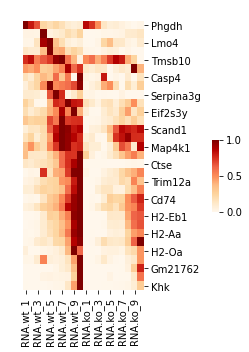

In [46]:
avepdclo = avepdclo[col]
avepdclo = avepdclo.reindex(row)
g = sns.clustermap(avepdclo, 
                   cmap="OrRd", 
                   #vmin=-2, 
                   vmax=1,
                   #center=0,
                   metric="correlation",
                   method="average",
                   col_cluster=False,
                   row_cluster=False, 
                   figsize= (3, 5),
                   dendrogram_ratio=(.1, 0.05),
                   cbar_pos=(1, 0.4, .03, .2))

In [23]:
l = list(avepdclo.iloc[g.dendrogram_row.reordered_ind].index.values)[::-1]
l

AttributeError: 'NoneType' object has no attribute 'reordered_ind'

In [47]:
g.savefig('DEGFigure/pdcwt.pdf')

In [8]:
avepdc = pd.read_csv('~/scRNAseq/analysis/data/yhat4.csv', index_col = 0)
avepdc = avepdc.sub(avepdc.min(axis=1),axis=0)
avepdc = avepdc.divide(avepdc.max(axis=1),axis=0)



[]

In [12]:
bin = 50
col = ['RNA.ko_{}'.format(i+1) for i in range(bin)] + ['RNA.wt_{}'.format(i+1) for i in range(bin)]
col

avepdc.columns = col
avepdc = avepdc[,:25]

,RNA.ko_1,RNA.ko_2,RNA.ko_3,RNA.ko_4,RNA.ko_5,RNA.ko_6,RNA.ko_7,RNA.ko_8,RNA.ko_9,RNA.ko_10,...,RNA.wt_41,RNA.wt_42,RNA.wt_43,RNA.wt_44,RNA.wt_45,RNA.wt_46,RNA.wt_47,RNA.wt_48,RNA.wt_49,RNA.wt_50
Rnpep,1.000000,0.944572,0.892152,0.842649,0.795971,0.752017,0.710682,0.671860,0.635444,0.601326,...,1.723166e-02,1.527160e-02,1.329826e-02,1.132381e-02,9.359314e-03,7.414776e-03,5.499147e-03,3.620344e-03,1.785298e-03,0.000000
Dbi,1.000000,0.947704,0.898114,0.851337,0.807441,0.766464,0.728417,0.693292,0.661067,0.631709,...,2.228788e-02,1.391455e-02,7.957301e-03,3.923497e-03,1.439876e-03,2.128268e-04,0.000000e+00,5.894601e-04,1.784121e-03,0.003390
Emb,1.000000,0.976486,0.952835,0.928423,0.902692,0.875162,0.845434,0.813201,0.778263,0.740535,...,1.743348e-02,1.494605e-02,1.262286e-02,1.045084e-02,8.418130e-03,6.513976e-03,4.728594e-03,3.053085e-03,1.479349e-03,0.000000
Pim1,1.000000,0.992850,0.985530,0.977825,0.969530,0.960445,0.950382,0.939160,0.926615,0.912596,...,6.159488e-02,5.591703e-02,5.107911e-02,4.693493e-02,4.336106e-02,4.025170e-02,3.751481e-02,3.506913e-02,3.284189e-02,0.030767
Slamf1,1.000000,0.963370,0.928147,0.894350,0.861989,0.831067,0.801579,0.773516,0.746865,0.721607,...,6.793767e-03,5.849498e-03,4.957868e-03,4.116548e-03,3.323245e-03,2.575706e-03,1.871731e-03,1.209169e-03,5.859339e-04,0.000000
Gm47283,0.975273,0.982409,0.989033,0.994565,0.998417,1.000000,0.998733,0.994059,0.985464,0.972492,...,7.187498e-03,7.266979e-03,7.435764e-03,7.685539e-03,8.008441e-03,8.396786e-03,8.842821e-03,9.338509e-03,9.875336e-03,0.010444
Mid1,0.929298,0.945007,0.960226,0.974157,0.985963,0.994780,0.999740,1.000000,0.994774,0.983373,...,3.433012e-02,3.487127e-02,3.555253e-02,3.636597e-02,3.730387e-02,3.835831e-02,3.952082e-02,4.078201e-02,4.213125e-02,0.043556
Cd34,0.662858,0.712670,0.764671,0.817165,0.868014,0.914658,0.954199,0.983560,0.999718,1.000000,...,9.027341e-03,9.587670e-03,1.011580e-02,1.061271e-02,1.108046e-02,1.152211e-02,1.194167e-02,1.234400e-02,1.273475e-02,0.013120
Wdfy1,0.704709,0.740280,0.776497,0.812710,0.848182,0.882093,0.913553,0.941609,0.965270,0.983532,...,4.318097e-02,5.533251e-02,6.904053e-02,8.431845e-02,1.011780e-01,1.196260e-01,1.396609e-01,1.612689e-01,1.844200e-01,0.209064
Il12a,0.175935,0.212971,0.256664,0.307545,0.365886,0.431573,0.503946,0.581661,0.662558,0.743609,...,9.180691e-02,8.130320e-02,6.864357e-02,5.525731e-02,4.229208e-02,3.052670e-02,2.038018e-02,1.197956e-02,5.249915e-03,0.000000


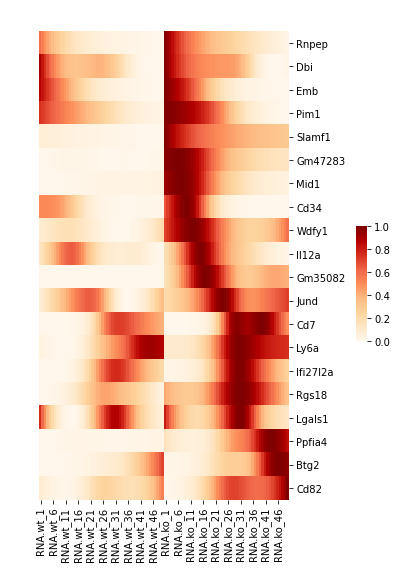

In [26]:
g = sns.clustermap(avepdc, 
                   cmap="OrRd", 
                   #vmin=-2, 
                   vmax=1,
                   #center=0,
                   metric="correlation",
                   method="average",
                   col_cluster=False,
                   row_cluster=False, 
                   figsize= (5, 8),
                   dendrogram_ratio=(.1, 0.05),
                   cbar_pos=(1, 0.4, .03, .2))

In [23]:
avepdc = pd.concat([avepdc.iloc[:,50:], avepdc.iloc[:,:50]], axis=1)

In [25]:
g.savefig('DEGFigure/pdcdown-smooth.pdf')